In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [3]:
df.info()
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   str    
 6   STATUS            2823 non-null   str    
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   str    
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   str    
 13  CUSTOMERNAME      2823 non-null   str    
 14  PHONE             2823 non-null   str    
 15  ADDRESSLINE1      2823 non-null   str    
 16  ADDRESSLINE2      302 non-null    str    
 17  CITY  

(2823, 25)

In [4]:
df.isnull().sum()

ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64

In [5]:
X = df[["QUANTITYORDERED", "PRICEEACH", "SALES", "MSRP"]]
X = X.fillna(X.mean())

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [7]:
wcss = []
for k in range(1,11) :
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

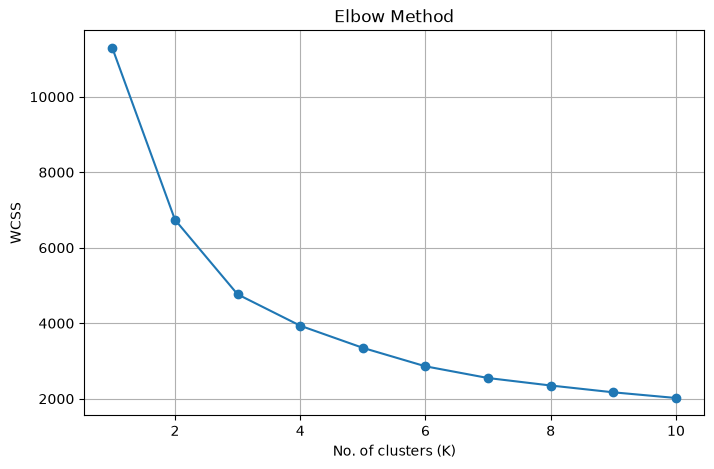

In [8]:
plt.figure(figsize = (8,5))
plt.plot(range(1,11), wcss, marker='o')
plt.title("Elbow Method")
plt.xlabel("No. of clusters (K)")
plt.ylabel("WCSS")
plt.grid()
plt.show()

In [9]:
k = 3
kmeans = KMeans(n_clusters = k, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)
print("K Means Cluster count : ")
print(df['KMeans_Cluster'].value_counts().sort_index())


K Means Cluster count : 
KMeans_Cluster
0    975
1    852
2    996
Name: count, dtype: int64


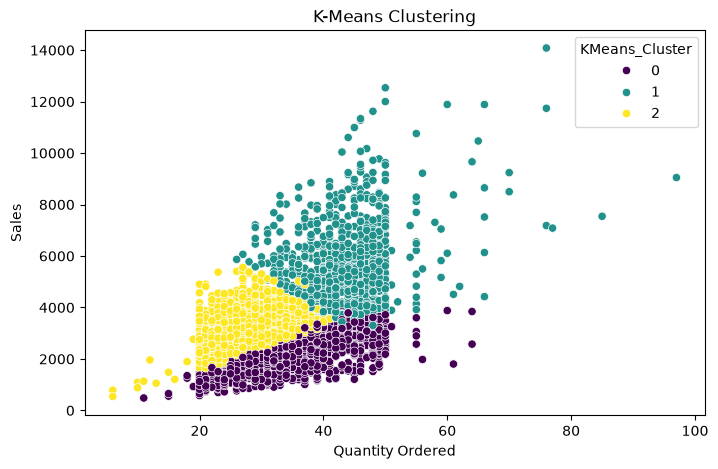

In [10]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=df['QUANTITYORDERED'], y=df['SALES'], hue=df['KMeans_Cluster'], palette='viridis')
plt.title("K-Means Clustering")
plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.show()

In [11]:
linked = linkage(X_scaled, method='ward')

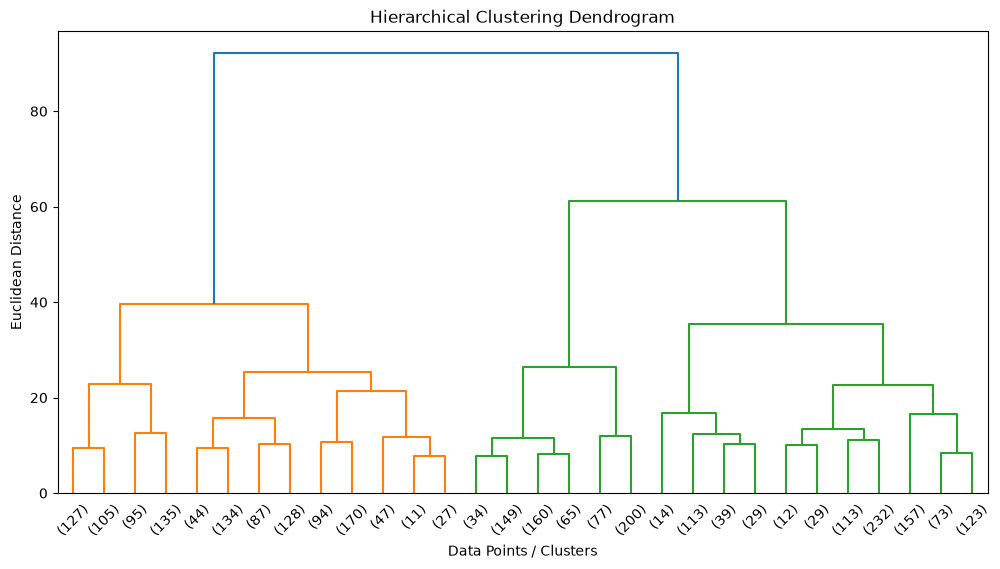

In [12]:
plt.figure(figsize=(12, 6))
dendrogram(linked, truncate_mode='lastp', p=30)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points / Clusters")
plt.ylabel("Euclidean Distance")
plt.show()

In [13]:
hierarchical = AgglomerativeClustering(n_clusters=k, linkage='ward')
df['Hierarchical_Cluster'] = hierarchical.fit_predict(X_scaled)
print("Hierarchical Cluster Counts : ")
print(df['Hierarchical_Cluster'].value_counts().sort_index())

Hierarchical Cluster Counts : 
Hierarchical_Cluster
0    1204
1     934
2     685
Name: count, dtype: int64


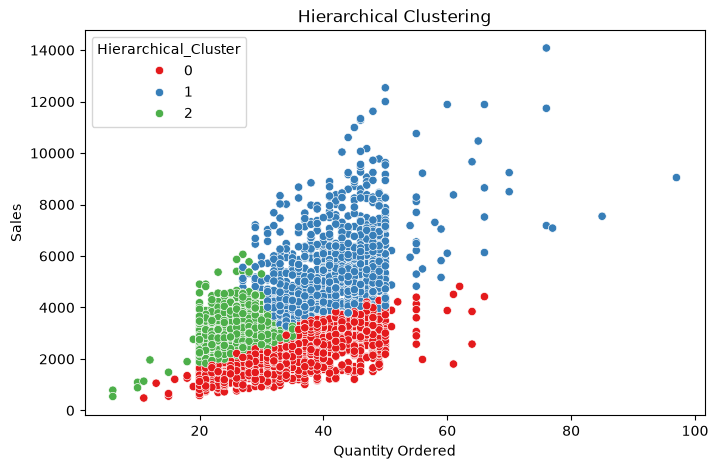

In [14]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=df['QUANTITYORDERED'], y=df['SALES'], hue=df['Hierarchical_Cluster'], palette='Set1')
plt.title("Hierarchical Clustering")
plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.show()

In [15]:
print("Final Clustered Dataset:")
print(df[['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'KMeans_Cluster', 'Hierarchical_Cluster']].head(10))

Final Clustered Dataset:
   QUANTITYORDERED  PRICEEACH    SALES  KMeans_Cluster  Hierarchical_Cluster
0               30      95.70  2871.00               2                     2
1               34      81.35  2765.90               2                     2
2               41      94.74  3884.34               1                     0
3               45      83.26  3746.70               1                     0
4               49     100.00  5205.27               1                     1
5               36      96.66  3479.76               2                     0
6               29      86.13  2497.77               2                     2
7               48     100.00  5512.32               1                     1
8               22      98.57  2168.54               2                     2
9               41     100.00  4708.44               1                     1


In [16]:
print("K-Means Cluster Analysis : ")
print(df.groupby('KMeans_Cluster')[['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']].mean().round(2))

K-Means Cluster Analysis : 
                QUANTITYORDERED  PRICEEACH    SALES    MSRP
KMeans_Cluster                                             
0                         35.21      59.55  2101.08   64.15
1                         43.72      97.48  5720.08  127.89
2                         27.60      95.44  3123.06  113.27
